<a href="https://colab.research.google.com/github/Beach4/gia-huy/blob/main/Mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_absolute_error

sns.set_theme(style="whitegrid")

# Tên file để lưu trong mục Tệp (Files) bên trái màn hình
raw_file_name = "weather_raw.csv"
clean_file_name = "weather_cleaned_final.csv"

# =====================================================================
# BƯỚC 1: THU THẬP VÀ IN DỮ LIỆU THÔ (RAW DATA)
# =====================================================================
print("--- [BƯỚC 1]: THU THẬP VÀ HIỂN THỊ DỮ LIỆU THÔ (RAW DATA) ---")

# Kiểm tra nếu file thô đã tồn tại thì đọc lên, chưa thì tải từ API
if os.path.exists(raw_file_name):
    df_raw = pd.read_csv(raw_file_name)
    print(f"-> Đã tải sẵn file dữ liệu thô từ tệp: '{raw_file_name}'")
else:
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": 21.0285,
        "longitude": 105.8542,
        "start_date": "2024-01-01",
        "end_date": "2024-12-31",
        "hourly": ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "surface_pressure", "cloud_cover"]
    }

    response = requests.get(url, params=params)
    data_json = response.json()

    if "hourly" in data_json:
        hourly_data = data_json["hourly"]
        df_raw = pd.DataFrame({
            'time': hourly_data['time'],
            'temperature': hourly_data['temperature_2m'],
            'humidity': hourly_data['relative_humidity_2m'],
            'wind_speed': hourly_data['wind_speed_10m'],
            'pressure': hourly_data['surface_pressure'],
            'cloud_cover': hourly_data['cloud_cover']
        })

        # 🌟 LƯU FILE DỮ LIỆU THÔ VÀO MỤC TỆP (FILES)
        df_raw.to_csv(raw_file_name, index=False)
        print(f"-> Đã lưu thành công file dữ liệu thô vào: '{raw_file_name}'")

print(f"👉 Kích thước Data Thô ban đầu: {df_raw.shape[0]} dòng, {df_raw.shape[1]} cột")
print(f"👉 Số lượng giá trị thiếu (NaN) trong Data Thô:")
print(df_raw.isnull().sum())

print("\n👉 10 dòng đầu tiên của DỮ LIỆU THÔ (RAW DATA):")
print(df_raw.head(10))
print("="*70)


--- [BƯỚC 1]: THU THẬP VÀ HIỂN THỊ DỮ LIỆU THÔ (RAW DATA) ---
-> Đã tải sẵn file dữ liệu thô từ tệp: 'weather_raw.csv'
👉 Kích thước Data Thô ban đầu: 8784 dòng, 6 cột
👉 Số lượng giá trị thiếu (NaN) trong Data Thô:
time           0
temperature    0
humidity       0
wind_speed     0
pressure       0
cloud_cover    0
dtype: int64

👉 10 dòng đầu tiên của DỮ LIỆU THÔ (RAW DATA):
               time  temperature  humidity  wind_speed  pressure  cloud_cover
0  2024-01-01T00:00         18.1        97         4.9    1015.1          100
1  2024-01-01T01:00         20.0        89         1.9    1016.5           67
2  2024-01-01T02:00         21.7        79         3.8    1017.1           59
3  2024-01-01T03:00         23.2        69         5.2    1016.9           33
4  2024-01-01T04:00         24.9        63         7.5    1016.1           34
5  2024-01-01T05:00         26.5        58        11.7    1015.1           67
6  2024-01-01T06:00         26.5        58        12.7    1013.6           74

In [24]:
# BƯỚC 2: QUÁ TRÌNH LÀM SẠCH VÀ XỬ LÝ DỮ LIỆU (CLEANING & PROCESSING)
print("\n--- [BƯỚC 2]: QUÁ TRÌNH LÀM SẠCH VÀ XỬ LÝ ---")

# Khởi tạo df_clean từ df_raw
df_clean = df_raw.copy()


# ============================================================
# 2.1: LỌC NGƯỠNG VẬT LÝ
# ============================================================

# Chuyển cột time sang kiểu datetime
df_clean['time'] = pd.to_datetime(df_clean['time'])

# Sắp xếp dữ liệu theo thời gian
df_clean = df_clean.sort_values('time').reset_index(drop=True)

# Lọc các giá trị nằm trong ngưỡng vật lý đã chọn
df_clean = df_clean[
    (df_clean['temperature'] >= 5) &
    (df_clean['temperature'] <= 43) &

    (df_clean['humidity'] >= 0) &
    (df_clean['humidity'] <= 100) &

    (df_clean['wind_speed'] >= 0) &
    (df_clean['wind_speed'] <= 120) &

    (df_clean['pressure'] >= 990) &
    (df_clean['pressure'] <= 1030) &

    (df_clean['cloud_cover'] >= 0) &
    (df_clean['cloud_cover'] <= 100)
].copy()

print("Số dòng sau khi lọc ngưỡng vật lý:", len(df_clean))


# ============================================================
# 2.2: LỌC NGOẠI LAI IQR THEO TỪNG THÁNG
# ============================================================

# Tạo cột tháng
df_clean['month'] = df_clean['time'].dt.month

# Các cột cần lọc ngoại lai
numeric_cols = [
    'temperature',
    'humidity',
    'wind_speed',
    'pressure'
]

# Lưu dữ liệu đã lọc
filtered_dfs = []

# Chia dữ liệu theo từng tháng
for month, group in df_clean.groupby('month'):

    # Tạo bản sao dữ liệu của tháng
    group_clean = group.copy()

    # Ban đầu giữ lại tất cả các hàng
    mask = pd.Series(True, index=group.index)

    # Tính IQR riêng cho từng cột
    for col in numeric_cols:

        # Tính Q1 và Q3 trên dữ liệu gốc của tháng
        Q1 = group[col].quantile(0.25)
        Q3 = group[col].quantile(0.75)

        # Tính khoảng tứ phân vị
        IQR = Q3 - Q1

        # Tính ngưỡng ngoại lai
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Cập nhật điều kiện giữ lại dữ liệu
        mask &= (
            (group[col] >= lower_bound) &
            (group[col] <= upper_bound)
        )

    # Giữ lại các hàng thỏa mãn tất cả điều kiện
    group_clean = group_clean[mask]

    # Thêm dữ liệu tháng vào danh sách
    filtered_dfs.append(group_clean)

# Ghép dữ liệu các tháng
df_iqr = pd.concat(filtered_dfs)

# Sắp xếp lại theo thời gian
df_iqr = df_iqr.sort_values('time').reset_index(drop=True)

print("Số dòng sau khi lọc IQR:", len(df_iqr))


# ============================================================
# 2.3: TẠO LAG FEATURES ĐÚNG THEO THỜI GIAN
# ============================================================

# Lấy dữ liệu nguồn trước khi lọc IQR
# Dùng dữ liệu này để tra nhiệt độ ở đúng thời điểm quá khứ

temperature_source = df_clean.set_index('time')['temperature']

# Tạo thời điểm cần lấy nhiệt độ giờ trước
time_lag_1 = df_iqr['time'] - pd.Timedelta(hours=1)

# Tạo thời điểm cần lấy nhiệt độ 24 giờ trước
time_lag_24 = df_iqr['time'] - pd.Timedelta(hours=24)

# Tra nhiệt độ tại đúng thời điểm giờ trước
df_iqr['temp_lag_1'] = (
    temperature_source.reindex(time_lag_1).to_numpy()
)

# Tra nhiệt độ tại đúng thời điểm 24 giờ trước
df_iqr['temp_lag_24'] = (
    temperature_source.reindex(time_lag_24).to_numpy()
)


# ============================================================
# 2.4: TẠO ĐẶC TRƯNG THỜI GIAN
# ============================================================

# Tạo đặc trưng giờ
df_iqr['hour'] = df_iqr['time'].dt.hour

# Giữ lại đặc trưng tháng
df_iqr['month'] = df_iqr['time'].dt.month


# ============================================================
# 2.5: XỬ LÝ GIÁ TRỊ THIẾU PHÁT SINH TỪ LAG
# ============================================================

# Đếm số dòng thiếu Lag trước khi xử lý
missing_lag = df_iqr[
    ['temp_lag_1', 'temp_lag_24']
].isnull().sum()

print("\nSố giá trị thiếu trong Lag:")
print(missing_lag)
# Giữ lại toàn bộ dữ liệu, chưa xóa các dòng thiếu Lag
df_clean = df_iqr.copy()

# Đánh lại chỉ số
df_clean = df_clean.sort_values('time').reset_index(drop=True)

# Hiển thị kết quả
print("\n-> Hoàn tất làm sạch dữ liệu!")

print("Số dòng Data sạch:", len(df_clean))

print("Số dòng bị loại:", len(df_raw) - len(df_clean))

print("=" * 60)

# =====================================================================
# BƯỚC 3: IN KẾT QUẢ DỮ LIỆU ĐÃ LÀM SẠCH RA MÀN HÌNH
# =====================================================================
print("\n--- [BƯỚC 3]: HIỂN THỊ MẪU DỮ LIỆU ĐÃ LÀM SẠCH (CLEANED DATA) ---")
print(df_clean.head(10))  # In ra 10 dòng đầu tiên của dữ liệu đã làm sạch

# (Tùy chọn) Lưu file dữ liệu đã làm sạch ra máy
df_clean.to_csv("weather_cleaned_final.csv", index=False)
print("\n👉 Đã lưu dữ liệu sạch thành công vào file: 'weather_cleaned_final.csv'")


--- [BƯỚC 2]: QUÁ TRÌNH LÀM SẠCH VÀ XỬ LÝ ---
Số dòng sau khi lọc ngưỡng vật lý: 8775
Số dòng sau khi lọc IQR: 8617

Số giá trị thiếu trong Lag:
temp_lag_1      1
temp_lag_24    33
dtype: int64

-> Hoàn tất làm sạch dữ liệu!
Số dòng Data sạch: 8617
Số dòng bị loại: 167

--- [BƯỚC 3]: HIỂN THỊ MẪU DỮ LIỆU ĐÃ LÀM SẠCH (CLEANED DATA) ---
                 time  temperature  humidity  wind_speed  pressure  \
0 2024-01-01 00:00:00         18.1        97         4.9    1015.1   
1 2024-01-01 01:00:00         20.0        89         1.9    1016.5   
2 2024-01-01 02:00:00         21.7        79         3.8    1017.1   
3 2024-01-01 03:00:00         23.2        69         5.2    1016.9   
4 2024-01-01 04:00:00         24.9        63         7.5    1016.1   
5 2024-01-01 05:00:00         26.5        58        11.7    1015.1   
6 2024-01-01 06:00:00         26.5        58        12.7    1013.6   
7 2024-01-01 07:00:00         26.9        58        14.6    1012.3   
8 2024-01-01 08:00:00         26


--- [BƯỚC 4]: HUẤN LUYỆN MÔ HÌNH VÀ ĐÁNH GIÁ ---
Số mẫu Train: 6893
Số mẫu Test: 1724
Số giá trị thiếu trong Train: 0
Số giá trị thiếu trong Test: 0

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---
1. MSE: 0.7251
2. MAE: 0.6545 °C
3. R2 Score: 0.9664


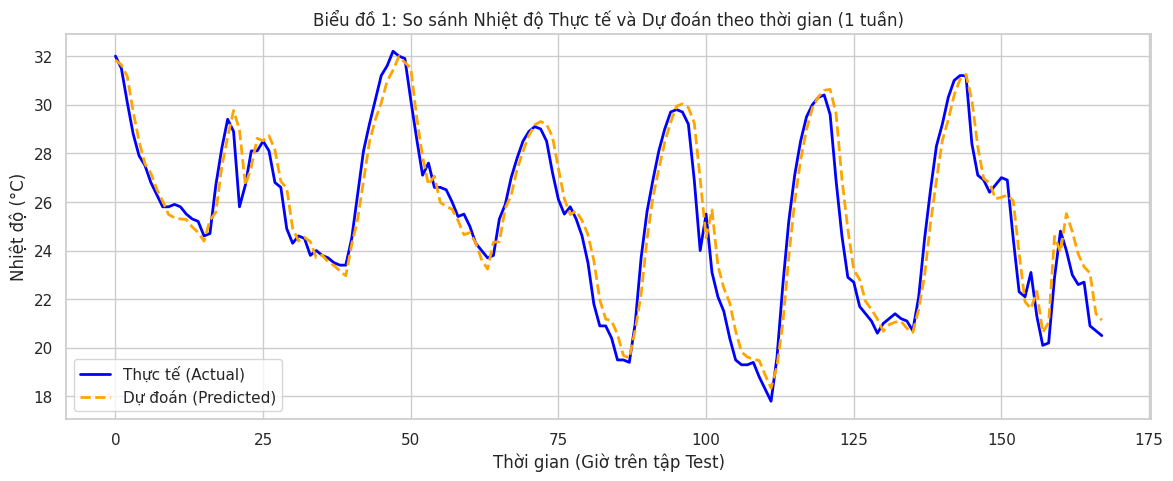

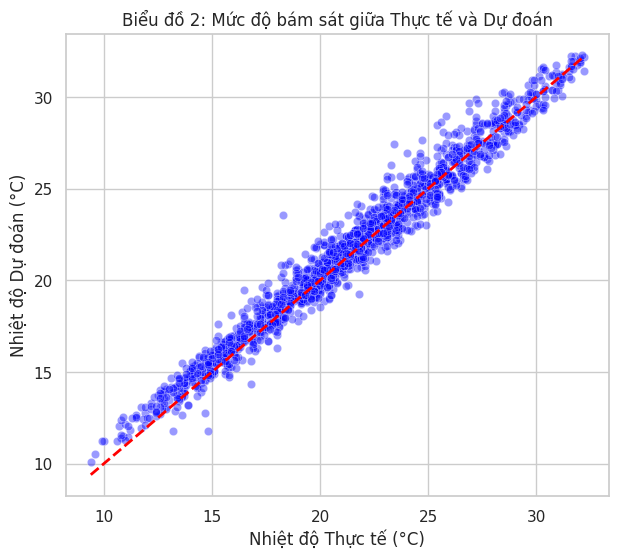

In [26]:
print("\n--- [BƯỚC 4]: HUẤN LUYỆN MÔ HÌNH VÀ ĐÁNH GIÁ ---")
# 1. Sắp xếp dữ liệu theo thời gian (sử dụng df_iqr có đầy đủ cột đặc trưng trễ)
df_clean = df_iqr.sort_values('time').reset_index(drop=True)

# 2. Chọn các đặc trưng đầu vào
selected_features = [
    'humidity', 'wind_speed', 'pressure', 'cloud_cover',
    'hour', 'month', 'temp_lag_1', 'temp_lag_24'
]

# 3. Tạo X và y
X = df_clean[selected_features].copy()
y = df_clean['temperature'].values

# 4. Chia dữ liệu theo thời gian: 80% Train, 20% Test
split_idx = int(len(X) * 0.8)

X_train = X.iloc[:split_idx].copy()
X_test = X.iloc[split_idx:].copy()

y_train = y[:split_idx]
y_test = y[split_idx:]

# 5. Điền giá trị thiếu của Lag bằng trung vị
lag_cols = ['temp_lag_1', 'temp_lag_24']

# Tính trung vị từ tập Train
lag_medians = X_train[lag_cols].median()

# Điền giá trị thiếu ở Train và Test
X_train[lag_cols] = X_train[lag_cols].fillna(lag_medians)
X_test[lag_cols] = X_test[lag_cols].fillna(lag_medians)

# Chuyển DataFrame thành mảng NumPy
X_train = X_train.to_numpy(dtype=float)
X_test = X_test.to_numpy(dtype=float)

# 6. Tính Mean và Standard Deviation từ Train
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

# Tránh chia cho 0 khi độ lệch chuẩn bằng 0
std[std == 0] = 1

# 7. Chuẩn hóa Train và Test
X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

# 8. Kiểm tra kết quả
print("Số mẫu Train:", len(X_train))
print("Số mẫu Test:", len(X_test))
print("Số giá trị thiếu trong Train:", np.isnan(X_train_scaled).sum())
print("Số giá trị thiếu trong Test:", np.isnan(X_test_scaled).sum())

class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, epochs=800):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for epoch in range(self.epochs):
            y_pred = np.dot(X, self.weights) + self.bias
            dw = (2 / n_samples) * np.dot(X.T, (y_pred - y))
            db = (2 / n_samples) * np.sum(y_pred - y)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

gd_model = LinearRegressionGD(learning_rate=0.05, epochs=800)
gd_model.fit(X_train_scaled, y_train)
y_pred_gd = gd_model.predict(X_test_scaled)

mse = np.mean((y_test - y_pred_gd) ** 2)
mae = mean_absolute_error(y_test, y_pred_gd)
r2 = r2_score(y_test, y_pred_gd)

print(f"\n--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---")
print(f"1. MSE: {mse:.4f}")
print(f"2. MAE: {mae:.4f} °C")
print(f"3. R2 Score: {r2:.4f}")
# BIỂU ĐỒ 1: Biểu đồ đường Chuỗi thời gian (Actual vs Predicted theo 1 tuần / 168 giờ)
plt.figure(figsize=(14, 5))
plt.plot(y_test[:168], label='Thực tế (Actual)', color='blue', linewidth=2)
plt.plot(y_pred_gd[:168], label='Dự đoán (Predicted)', color='orange', linestyle='--', linewidth=2)
plt.xlabel("Thời gian (Giờ trên tập Test)")
plt.ylabel("Nhiệt độ (°C)")
plt.title("Biểu đồ 1: So sánh Nhiệt độ Thực tế và Dự đoán theo thời gian (1 tuần)")
plt.legend()
plt.show()

# BIỂU ĐỒ 2: Biểu đồ Scatter (Thực tế vs Dự đoán kèm đường chuẩn lý tưởng)
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=y_pred_gd, alpha=0.4, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', lw=2)
plt.xlabel("Nhiệt độ Thực tế (°C)")
plt.ylabel("Nhiệt độ Dự đoán (°C)")
plt.title("Biểu đồ 2: Mức độ bám sát giữa Thực tế và Dự đoán")
plt.show()